# Braun et al. (2026), Fig. 4 — sequences reset after structured perturbations (WP0.5)

> A: ensemble × time-window grid. B, E, F: firing rate of one neuron under silencing, current injection and noise
> injection. C: unperturbed response, silencing (100 neurons, 1.7 s), current injection (I = 3) and noise injection
> (50% of neurons, gain 15, first 8.5 s). D: components of the total input under current injection.
> G, H (bat, mouse data) are blocked on [DATA].

**Panels:** A grid · B silencing trace · C four responses · D input components · E current trace · F noise trace ·
G (added) reset location predicted from the profile minimum (spec WP0.5 new measurement).

**Acceptance (spec WP0.5, qualitative):** silencing an active ensemble resets the sequence; current injection with
I ≥ 2 restarts it from the injected ensemble; noise leaves it intact except at high gain and fraction (Supp. 9).

Protocols: `seqnet.analysis.perturb` (Braun Methods lines 1130–1222). The network is realisation 1 of the
a = 0.6, σ = 1 s, b = 0 condition (`configs/wp0/braun_fig4.yaml`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet import conventions as cv
from seqnet.sequences import braun_sequence, logit_target
from seqnet.models.rate_rnn import simulate, RNNParams, Perturbation
from seqnet.analysis import perturb as pt
from seqnet.analysis.profile_features import preprocess_profile

style()
fig = Figure("wp0", "braun_fig4")
cfg = fig.config(); tg = cfg["target"]
run = wp0.get(tg["amp"], tg["width"], tg["offset"], cfg["settings"])
J = run.W(cfg["realisation"])
spec = braun_sequence(amp=tg["amp"], width=tg["width"], offset=tg["offset"])
N = spec.N; prm = RNNParams(); dt = prm.dt
h0 = logit_target(spec, 0.0)[:, 0]
ens = pt.ensembles(N, cfg["f_E"]); ex = cfg["example"]; E = ens[ex["ensemble"]]
w0, w1 = ex["window"] * cfg["window_steps"], (ex["window"] + 1) * cfg["window_steps"]
half = cfg["n_steps"] // 2
def sim(perts, rec_inputs=False):
    return simulate(J, h0, cfg["n_steps"], prm, np.random.default_rng(cfg["seed"]), perturbations=perts, record_inputs=rec_inputs)
run.meta["settings"], run.summary["corr"][cfg["realisation"], -1]

('dev', np.float64(0.9151237913241649))

In [2]:
Q = np.random.default_rng(1).choice(N, int(cfg["noise"]["fraction"] * N), replace=False)
r_un = sim([])["r"]
r_si = sim([Perturbation("silence", E, w0, w1)])["r"]
cur = sim([Perturbation("current", E, w0, w1, cfg["current"])], rec_inputs=True)
r_cu, z_cu = cur["r"], cur["z"]
r_no = sim([Perturbation("noise", Q, 0, half, cfg["noise"]["gain"])])["r"]
t = np.arange(cfg["n_steps"]) * dt
sub = slice(None, None, 4)
fig.save("responses", params=cfg, t=t[sub], r_un=r_un[sub].T.astype(np.float32), r_si=r_si[sub].T.astype(np.float32),
         r_cu=r_cu[sub].T.astype(np.float32), r_no=r_no[sub].T.astype(np.float32), E=E, Q=Q, w=np.array([w0, w1]) * dt)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig4/responses.npz')

## Panel A — ensemble × time-window grid on the unperturbed response

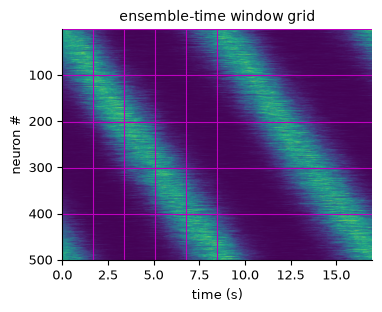

In [3]:
d = fig.load("responses")
F, ax = plt.subplots(figsize=(4, 3))
ax.imshow(d["r_un"], aspect="auto", extent=[0, d["t"][-1], N, 1], vmin=0, vmax=1)
for e in ens: ax.axhline(e[0] + 1, color="m", lw=0.8)
for k in range(cfg["n_windows"] + 1): ax.axvline(k * cfg["window_steps"] * dt, color="m", lw=0.8)
ax.set_xlabel("time (s)"); ax.set_ylabel("neuron #"); ax.set_title("ensemble-time window grid")
fig.savefig("A_grid", F); plt.show()

## Panel C — unperturbed, silencing, current injection, noise injection

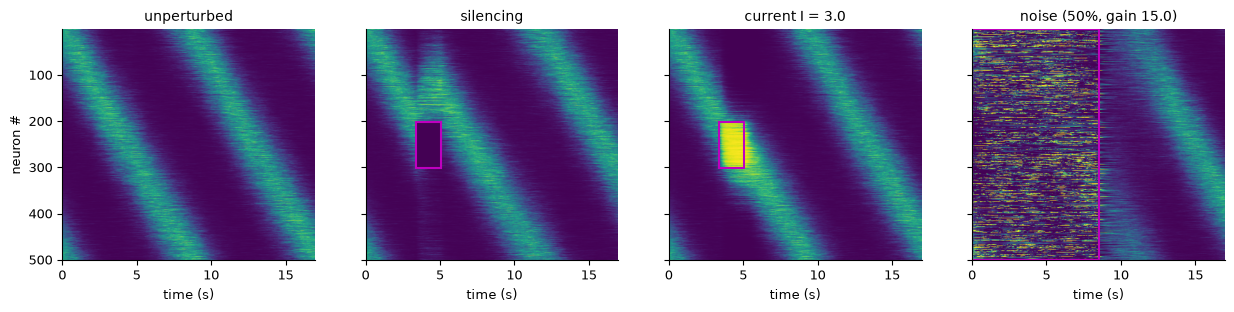

In [4]:
d = fig.load("responses")
F, axs = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, key, title in zip(axs, ["r_un", "r_si", "r_cu", "r_no"], ["unperturbed", "silencing", f"current I = {cfg['current']}", f"noise ({int(cfg['noise']['fraction']*100)}%, gain {cfg['noise']['gain']})"]):
    ax.imshow(d[key], aspect="auto", extent=[0, d["t"][-1], N, 1], vmin=0, vmax=1); ax.set_title(title); ax.set_xlabel("time (s)")
    if key in ("r_si", "r_cu"):
        ax.add_patch(plt.Rectangle((d["w"][0], d["E"][0] + 1), d["w"][1] - d["w"][0], len(d["E"]), fill=False, ec="m", lw=1.5))
    if key == "r_no":
        ax.add_patch(plt.Rectangle((0, 1), half * dt, N - 1, fill=False, ec="m", lw=1.5))
axs[0].set_ylabel("neuron #")
fig.savefig("C_responses", F); plt.show()

## Panels B, E, F — firing rate of one example neuron under each perturbation

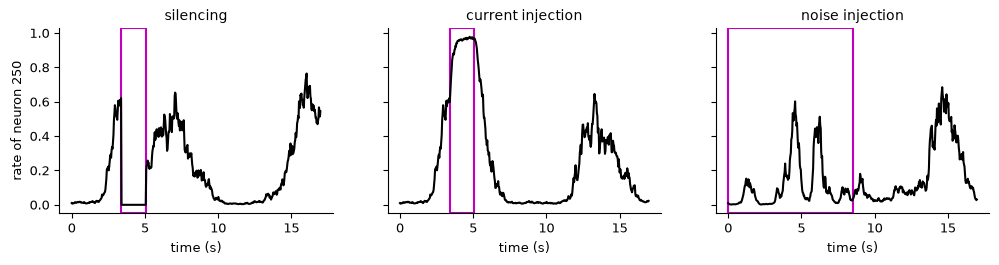

In [5]:
d = fig.load("responses"); i = cfg["example_neuron"]
F, axs = plt.subplots(1, 3, figsize=(12, 2.4), sharey=True)
for ax, key, title, win in zip(axs, ["r_si", "r_cu", "r_no"], ["silencing", "current injection", "noise injection"],
                               [d["w"], d["w"], (0, half * dt)]):
    ax.plot(d["t"], d[key][i], "k"); ax.axvspan(*win, fill=False, ec="m", lw=1.5); ax.set_title(title); ax.set_xlabel("time (s)")
axs[0].set_ylabel(f"rate of neuron {i}")
fig.savefig("BEF_traces", F); plt.show()

## Panel D — components of the input to the example neuron under current injection

In [6]:
i = cfg["example_neuron"]
from scipy.special import expit
rec = J @ r_cu.T  # recurrent term J r(t) (r already includes no silencing here)
inj = np.where((np.arange(cfg["n_steps"]) >= w0) & (np.arange(cfg["n_steps"]) < w1) & np.isin(i, E), cfg["current"], 0.0)
noise = z_cu[:, i] - rec[i] - inj
fig.save("D_components", t=t[sub], recurrent=rec[i][sub], noise=noise[sub], injected=inj[sub], total=z_cu[:, i][sub])

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig4/D_components.npz')

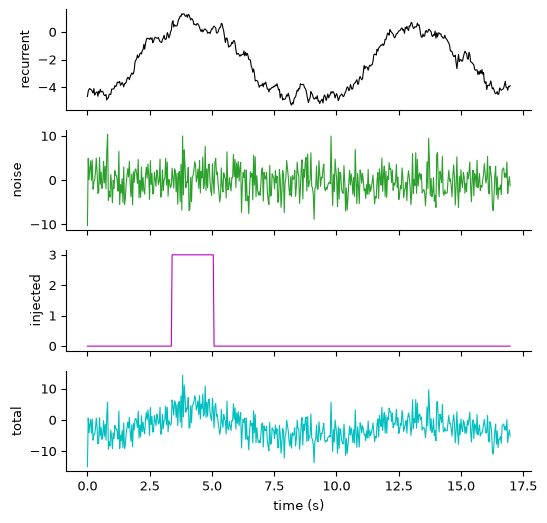

In [7]:
d = fig.load("D_components")
F, axs = plt.subplots(4, 1, figsize=(6, 6), sharex=True)
for ax, key, col in zip(axs, ["recurrent", "noise", "injected", "total"], ["k", "tab:green", "m", "c"]):
    ax.plot(d["t"], d[key], color=col, lw=0.8); ax.set_ylabel(key)
axs[-1].set_xlabel("time (s)")
fig.savefig("D_components", F); plt.show()

## Panel G (added) — reset location against the profile minimum (spec WP0.5)

Braun Supp. 8: "The ensemble to which the sequence resets is as far away from the silenced ensemble as the position
of the minimum in the connectivity profile." For every ensemble silenced in its own active window, the reset location
is the neuron with maximal rate averaged over 0.5 s after release, relative to the silenced ensemble's centre
(circular). The prediction is the distance of the smoothed profile's minimum (d ≠ 0) of this network.

In [8]:
grid = pt.structured_grid(J, h0, "silence", cfg["f_E"], params=prm, n_steps=cfg["n_steps"], window_steps=cfg["window_steps"],
                          n_windows=cfg["n_windows"], seed=cfg["seed"], keep_examples=[(i_, a_) for i_, a_ in enumerate(
                              [pt.active_window(r_un, e, cfg["window_steps"], cfg["n_windows"]) for e in ens])])
dd, s, _ = preprocess_profile(cv.profile_from_matrix(J))
nz = dd != 0
d_min = int(dd[nz][np.argmin(s[nz])])
meas = []
for (i_, a_), r in grid.examples.items():
    stop = (a_ + 1) * cfg["window_steps"]
    m = r[stop: stop + int(0.5 / dt)].mean(0)
    c = int(np.mean(ens[i_]))
    meas.append(((int(np.argmax(m)) - c + N // 2) % N) - N // 2)
fig.save("G_reset", d=dd, cp_smooth=s, d_min=d_min, measured=np.array(meas), CC=grid.CC, aligned_mean=grid.aligned_mean)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig4/G_reset.npz')

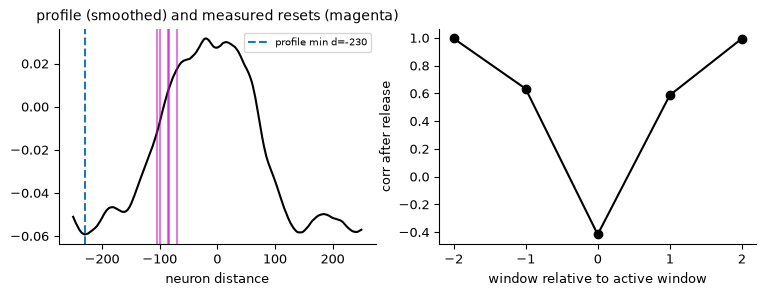

profile minimum at d = -230 ; measured reset offsets: [-104  -70  -86 -100  -84]


In [9]:
d = fig.load("G_reset")
F, axs = plt.subplots(1, 2, figsize=(9, 2.8))
axs[0].plot(d["d"], d["cp_smooth"], "k"); axs[0].axvline(int(d["d_min"]), color="tab:blue", ls="--", label=f"profile min d={int(d['d_min'])}")
for m_ in d["measured"]: axs[0].axvline(m_, color="m", alpha=0.5)
axs[0].legend(fontsize=7); axs[0].set_xlabel("neuron distance"); axs[0].set_title("profile (smoothed) and measured resets (magenta)")
axs[1].plot(np.arange(-2, 3), d["aligned_mean"], "ko-"); axs[1].set_xlabel("window relative to active window"); axs[1].set_ylabel("corr after release")
fig.savefig("G_reset", F); plt.show()
print("profile minimum at d =", int(d["d_min"]), "; measured reset offsets:", d["measured"])

## Acceptance

In [10]:
g = fig.load("G_reset"); am = g["aligned_mean"]
err = np.abs(np.abs(g["measured"]) - abs(int(g["d_min"])))
fig.checks([
    {"item": "silencing the active ensemble resets the sequence", "criterion": "aligned correlation at the active window < 0.5 and off-window > 0.8",
     "value": am, "passed": bool(am[2] < 0.5 and min(am[0], am[-1]) > 0.8)},
    {"item": "reset distance predicted by the profile minimum", "criterion": "reported: |measured| - |d_min| (neurons)",
     "value": {"d_min": int(g["d_min"]), "measured": g["measured"], "abs_error": err}, "passed": None},
])

[PASS] silencing the active ensemble resets the sequence: [ 0.99649384  0.63371783 -0.41598136  0.58684867  0.99502583]
[info] reset distance predicted by the profile minimum: {'d_min': -230, 'measured': array([-104,  -70,  -86, -100,  -84]), 'abs_error': array([126, 160, 144, 130, 146])}


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig4/acceptance.json')